# 03 - Model comparison

**Goal:** compare logistic regression, random forest, XGBoost and LightGBM on the validation year (2016), using the same time-based split, the same 12 features and the same metrics.

**Rules**
- Models are trained on 2003-2015 only and scored on 2016. The test year (2017) and the late-check years (2018-2019) are not touched.
- Each model handles class imbalance with its own weighting.
- At the fixed threshold of 0.5 the models are not directly comparable, because class weighting shifts their probabilities differently. The main comparison uses ROC-AUC and PR-AUC; thresholds are tuned in the next section.

import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL
from src.models.builders import all_models
from src.evaluation.metrics import evaluate

df = load_data()
train, validation, test, late = time_split(df)

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL
from src.models.builders import all_models
from src.evaluation.metrics import evaluate

df = load_data()
train, validation, test, late = time_split(df)

## 1. Train the four models and score them on validation

**Goal:** fit every model on the training period and record all metrics on 2016. The predicted probabilities are kept in `proba` for the threshold tuning that follows.

models = all_models(train[LABEL])

proba = {}
for name, model in models.items():
    model.fit(train[FEATURES], train[LABEL])
    proba[name] = model.predict_proba(validation[FEATURES])[:, 1]

results = pd.DataFrame({name: evaluate(validation[LABEL], p) for name, p in proba.items()})
results.round(3)

In [2]:
models = all_models(train[LABEL])

proba = {}
for name, model in models.items():
    model.fit(train[FEATURES], train[LABEL])
    proba[name] = model.predict_proba(validation[FEATURES])[:, 1]

results = pd.DataFrame({name: evaluate(validation[LABEL], p) for name, p in proba.items()})
results.round(3)

,logistic regression,random forest,xgboost,lightgbm
ROC-AUC,0.784,0.804,0.804,0.804
PR-AUC,0.601,0.633,0.631,0.630
precision,0.474,0.551,0.496,0.493
recall,0.772,0.697,0.792,0.793
F1,0.587,0.615,0.610,0.608
MCC,0.382,0.436,0.420,0.417
bug share,0.291,0.291,0.291,0.291


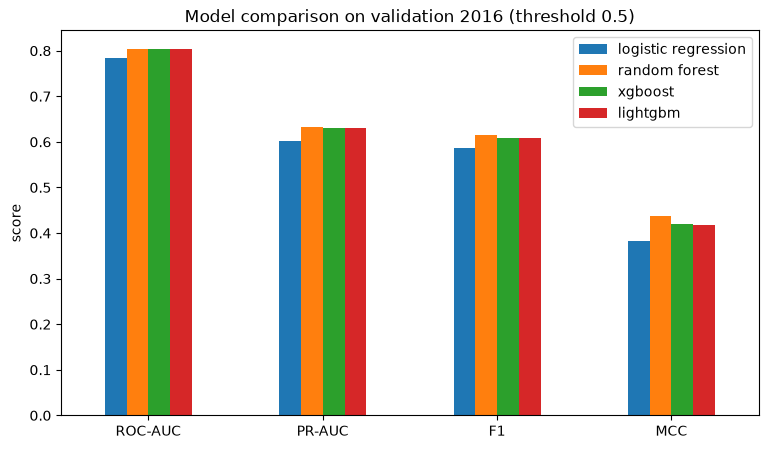

In [3]:
ax = results.loc[["ROC-AUC", "PR-AUC", "F1", "MCC"]].plot(kind="bar", figsize=(9, 5), rot=0, title="Model comparison on validation 2016 (threshold 0.5)")
ax.set_ylabel("score")
ax.figure.savefig("../reports/figures/03_model_comparison.png", dpi=150, bbox_inches="tight")
results.round(4).to_csv("../results/03_model_comparison_validation.csv")

**Observation**
- All three tree models beat the logistic regression baseline, but only modestly: ROC-AUC 0.804 vs 0.784 (+0.02) and PR-AUC about 0.63 vs 0.601 (+0.03). The scores are still far from perfect, in line with the weak single-feature signals seen in the EDA.
- Random forest, XGBoost and LightGBM are practically tied: their ROC-AUC is identical (0.804) and their PR-AUC differs by only 0.003. Differences below about 0.01 are treated as no real difference, so no model is picked yet.
- At the fixed threshold of 0.5 the models behave differently: random forest is more cautious (precision 0.551, recall 0.697, about 37% of commits flagged), while XGBoost and LightGBM catch more bugs (recall about 0.79) with lower precision (about 0.49) and flag about 46-47% of commits (computed from precision, recall and the bug share). These numbers are not a fair comparison because class weighting shifts each model's probabilities differently.

**Decision:** keep all four models for the next step, where each model gets its own threshold chosen on validation and is also judged with an effort-aware metric.

## 2. Thresholds and effort-aware metrics

**Goal:** give each model its own decision threshold and judge it the way a reviewer would use it.

- **Threshold:** for each model, the threshold in 0.05-0.95 that maximizes MCC on the validation year.
- **Recall@20%Effort:** if reviewers can read only 20% of all changed lines (`la` + `ld`), the share of bug-inducing commits found when commits are reviewed from the riskiest down. Two review orders are compared: by predicted probability, and by probability per changed line (`probability / (lines + 1)`), which puts small risky commits first.

**Caution:** thresholds are chosen and scored on the same year (2016), so these scores are slightly optimistic. They are used to compare models and to fix the thresholds; the test year will be evaluated once with the thresholds kept fixed.

In [4]:
import numpy as np
from src.evaluation.metrics import best_threshold, effort_curve, recall_at_effort

y_val = validation[LABEL]
effort = (validation["la"] + validation["ld"]).to_numpy()

rows = {}
for name, p in proba.items():
    t = best_threshold(y_val, p)
    row = evaluate(y_val, p, threshold=t)
    row["threshold"] = t
    row["flagged share"] = (p >= t).mean()
    row["Recall@20%Effort"] = recall_at_effort(y_val, p, effort, 0.2)
    row["Recall@20%Effort (per line)"] = recall_at_effort(y_val, p / (effort + 1), effort, 0.2)
    rows[name] = row

tuned = pd.DataFrame(rows)
tuned.round(4).to_csv("../results/03_tuned_validation.csv")
tuned.round(3)

,logistic regression,random forest,xgboost,lightgbm
ROC-AUC,0.784,0.804,0.804,0.804
PR-AUC,0.601,0.633,0.631,0.630
precision,0.547,0.584,0.569,0.578
recall,0.632,0.648,0.656,0.638
F1,0.586,0.614,0.610,0.607
MCC,0.401,0.445,0.435,0.435
bug share,0.291,0.291,0.291,0.291
threshold,0.620,0.550,0.640,0.660
flagged share,0.336,0.323,0.335,0.321
Recall@20%Effort,0.054,0.107,0.098,0.097


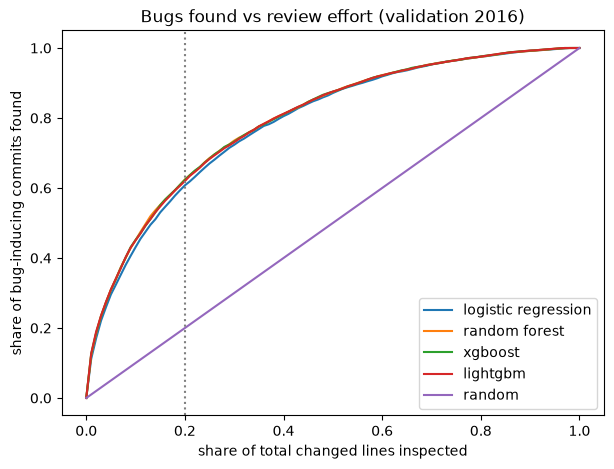

In [5]:
grid = np.linspace(0, 1, 101)
curves = {}
for name, p in proba.items():
    x, y = effort_curve(y_val, p / (effort + 1), effort)
    curves[name] = np.interp(grid, x, y)
curves["random"] = grid

ax = pd.DataFrame(curves, index=grid).plot(figsize=(7, 5), title="Bugs found vs review effort (validation 2016)")
ax.set_xlabel("share of total changed lines inspected")
ax.set_ylabel("share of bug-inducing commits found")
ax.axvline(0.2, color="gray", linestyle=":")
ax.figure.savefig("../reports/figures/03_effort_curves.png", dpi=150, bbox_inches="tight")